# Clustering the Military Powers of Countries

### This project aims to analyze the military power of countries and group them based on similar military capacities. By applying clustering algorithms, countries with comparable military strength are identified and visualized. The analysis helps reveal patterns among nations and provides insights into global military groupings using unsupervised machine learning techniques.


In [121]:
import pandas as pd
pd.set_option("display.max_columns",1000)

import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns

## Dataset Feature Description - Military Power of Countries

1. **Military Strength**: General textual information about military power.
2. **Military Strength Power Index**: Numeric index representing military power.

3. **Aircraft Strength**: Text description of air force capacity.
4. **Aircraft Strength Value**: Numeric value of air force strength.

5. **Fighter/Interceptor Strength**: Textual strength of fighter/interceptor aircraft.
6. **Fighter/Interceptor Strength Value**: Numeric strength of fighter/interceptor aircraft.

7. **Attack Aircraft Strength**: Text description of attack aircraft strength.
8. **Attack Aircraft Strength Value**: Numeric strength of attack aircraft.

9. **Transport Aircraft Fleet Strength**: Text info about transport aircraft fleet.
10. **Transport Aircraft Fleet Strength Value**: Numeric value of transport aircraft strength.

11. **Trainer Aircraft Fleet**: Text description of trainer aircraft fleet.
12. **Trainer Aircraft Fleet Value**: Numeric strength of trainer aircraft.

13. **Helicopter Fleet Strength**: Text description of helicopter strength.
14. **Helicopter Fleet Strength Value**: Numeric strength of helicopter fleet.

15. **Attack Helicopter Fleet Strength**: Text about attack helicopter fleet.
16. **Attack Helicopter Fleet Strength Value**: Numeric value of attack helicopter fleet.

17. **Tank Strength**: Textual tank strength information.
18. **Tank Strength Value**: Numeric value of tank strength.

19. **AFV/APC Strength**: Armored vehicles (AFV) and personnel carriers (APC) description.
20. **AFV/APC Strength Value**: Numeric value of AFV/APC strength.

21. **Self-Propelled Artillery Strength**: Text on self-propelled artillery.
22. **Self-Propelled Artillery Strength Value**: Numeric value of self-propelled artillery.

23. **Towed Artillery Strength**: Text info on towed artillery.
24. **Towed Artillery Strength Value**: Numeric value of towed artillery.

25. **Rocket Projector Strength**: Text description of rocket artillery.
26. **Rocket Projector Strength Value**: Numeric value of rocket projector strength.

27. **Navy Fleet Strengths**: Text about naval forces strength.
28. **Navy Fleet Strengths Value**: Numeric value of naval forces.

29. **Aircraft Carrier Fleet Strength**: Text on aircraft carrier strength.
30. **Aircraft Carrier Fleet Strength Value**: Numeric value of aircraft carrier fleet.

31. **Submarine Fleet Strength**: Text description of submarine strength.
32. **Submarine Fleet Strength Value**: Numeric value of submarine fleet.

33. **Destroyer Fleet Strength**: Text about destroyer fleet.
34. **Destroyer Fleet Strength Value**: Numeric destroyer fleet strength.

35. **Frigate Fleet Strength**: Text about frigate fleet.
36. **Frigate Fleet Strength Value**: Numeric value of frigate fleet.

37. **Defense Spending Budget**: Text on military budget.
38. **Defense Spending Budget Value**: Numeric defense spending value.

39. **External Debt**: Text description of national external debt.
40. **External Debt Value**: Numeric value of external debt.

41. **Airport Totals**: Text info on total number of airports.
42. **Airport Totals Value**: Numeric value of total airports.

43. **Oil Production**: Text about oil production level.
44. **Oil Production Value**: Numeric value of oil production.

45. **Oil Consumption**: Text on national oil consumption.
46. **Oil Consumption Value**: Numeric value of oil consumption.

47. **Proven Oil Reserves**: Text about proven oil reserves.
48. **Proven Oil Reserves Value**: Numeric value of oil reserves.

49. **Available Manpower**: Textual description of available manpower.
50. **Available Manpower Value**: Numeric value of manpower availability.

51. **Total Population**: Text description of total population.
52. **Total Population Value**: Numeric population size.

53. **Total Square Land Area**: Text info on land area.
54. **Total Square Land Area Value**: Numeric land area size.

55. **Total Coastline Coverage**: Text on coastline length.
56. **Total Coastline Coverage Value**: Numeric value of coastline length.

57. **Total Waterway Coverage**: Text about waterways.
58. **Total Waterway Coverage Value**: Numeric waterway length.

59. **Total Border Coverage**: Text on border length.
60. **Total Border Coverage Value**: Numeric value of border length.


In [122]:
df=pd.read_excel('World military power.xlsx',header=1)

## EDA - Exploratary Data Analysis

In [123]:
df.head()

,Military Strength,Military Strength Power Index,Aircraft Strength,Aircraft Strength value,Fighter/Interceptor Strength,Fighter/Interceptor Strength value,Attack Aircraft Strength,Attack Aircraft Strength value,Transport Aircraft Fleet Strength,Transport Aircraft Fleet Strength value,Trainer Aircraft Fleet,Trainer Aircraft Fleet value,Helicopter Fleet Strength,Helicopter Fleet Strength value,Attack Helicopter Fleet Strength,Attack Helicopter Fleet Strength value,Tank Strength,Tank Strength value,AFV/APC Strength,AFV/APC Strength value,Self-Propelled Artillery Strength,Self-Propelled Artillery Strength value,Towed Artillery Strength,Towed Artillery Strength value,Rocket Projector Strength,Rocket Projector Strength value,Navy Fleet Strengths,Navy Fleet Strengths value,Aircraft Carrier Fleet Strength,Aircraft Carrier Fleet Strength value,Submarine Fleet Strength,Submarine Fleet Strength value,Destroyer Fleet Strength,Destroyer Fleet Strength value,Frigate Fleet Strength,Frigate Fleet Strength value,defense spending budget,defense spending budget value,External Debt,External Debt value,Airport Totals,Airport Totals value,Oil Production,Oil Production value,Oil Consumption,Oil Consumption value,Proven Oil Reserves,Proven Oil Reserves value,Available Manpower,Available Manpower value,Total Population,Total Population value,Total Square Land Area,Total Square Land Area value,Total Coastline Coverage,Total Coastline Coverage value,Total Waterway Coverage,Total Waterway Coverage value,Total Border Coverage,Total Border Coverage value
0,Afghanistan,1.3444,Afghanistan,260,Afghanistan,0,Afghanistan,25,Afghanistan,30,Afghanistan,0,Afghanistan,187,Afghanistan,0,Afghanistan,0,Afghanistan,1062,Afghanistan,0,Afghanistan,176,Afghanistan,50,Afghanistan,0.0,Afghanistan,0.0,Afghanistan,0.0,Afghanistan,0.0,Afghanistan,0.0,Afghanistan,"12,00,00,00,000",Afghanistan,"2,84,00,00,000",Afghanistan,43,Afghanistan,0,Afghanistan,5500,Afghanistan,0,Afghanistan,"1,43,25,743",Afghanistan,"3,49,40,837",Afghanistan,"6,52,230",Afghanistan,0,Afghanistan,1200,Afghanistan,5987.0
1,Albania,2.3137,Albania,19,Albania,0,Albania,0,Albania,0,Albania,0,Albania,19,Albania,0,Albania,0,Albania,467,Albania,0,Albania,0,Albania,0,Albania,38.0,Albania,0.0,Albania,0.0,Albania,0.0,Albania,0.0,Albania,"25,00,00,000",Albania,"9,50,50,00,000",Albania,4,Albania,16000,Albania,42500,Albania,"16,83,00,000",Albania,"15,19,438",Albania,"30,57,220",Albania,28748,Albania,362,Albania,41,Albania,691.0
2,Algeria,0.4659,Algeria,551,Algeria,103,Algeria,22,Algeria,59,Algeria,87,Algeria,257,Algeria,45,Algeria,880,Algeria,7361,Algeria,320,Algeria,240,Algeria,316,Algeria,201.0,Algeria,0.0,Algeria,6.0,Algeria,0.0,Algeria,5.0,Algeria,"13,00,00,00,000",Algeria,"6,26,00,00,000",Algeria,157,Algeria,"13,06,000",Algeria,"3,25,000",Algeria,"12,20,00,00,000",Algeria,"2,07,41,263",Algeria,"4,16,57,488",Algeria,"23,81,741",Algeria,998,Algeria,0,Algeria,6734.0
3,Angola,0.8379,Angola,295,Angola,72,Angola,18,Angola,30,Angola,47,Angola,126,Angola,15,Angola,379,Angola,595,Angola,28,Angola,357,Angola,115,Angola,57.0,Angola,0.0,Angola,0.0,Angola,0.0,Angola,0.0,Angola,"7,00,00,00,000",Angola,"42,08,00,00,000",Angola,176,Angola,"16,66,000",Angola,82300,Angola,"8,27,30,00,000",Angola,"62,44,205",Angola,"3,03,55,880",Angola,"12,46,700",Angola,1600,Angola,1300,Angola,5369.0
4,Argentina,0.6521,Argentina,227,Argentina,24,Argentina,7,Argentina,9,Argentina,64,Argentina,100,Argentina,0,Argentina,370,Argentina,739,Argentina,83,Argentina,172,Argentina,26,Argentina,49.0,Argentina,0.0,Argentina,2.0,Argentina,4.0,Argentina,0.0,Argentina,"4,20,00,00,000",Argentina,"2,14,90,00,00,000",Argentina,1138,Argentina,"4,79,400",Argentina,"6,85,000",Argentina,"2,18,50,00,000",Argentina,"2,01,79,430",Argentina,"4,46,94,198",Argentina,"27,80,400",Argentina,4989,Argentina,11000,Argentina,11968.0


In [124]:
df.rename(columns={'Military Strength': 'country'}, inplace=True)

In [125]:
df.shape

(138, 60)

In [126]:
df.sample()

,country,Military Strength Power Index,Aircraft Strength,Aircraft Strength value,Fighter/Interceptor Strength,Fighter/Interceptor Strength value,Attack Aircraft Strength,Attack Aircraft Strength value,Transport Aircraft Fleet Strength,Transport Aircraft Fleet Strength value,Trainer Aircraft Fleet,Trainer Aircraft Fleet value,Helicopter Fleet Strength,Helicopter Fleet Strength value,Attack Helicopter Fleet Strength,Attack Helicopter Fleet Strength value,Tank Strength,Tank Strength value,AFV/APC Strength,AFV/APC Strength value,Self-Propelled Artillery Strength,Self-Propelled Artillery Strength value,Towed Artillery Strength,Towed Artillery Strength value,Rocket Projector Strength,Rocket Projector Strength value,Navy Fleet Strengths,Navy Fleet Strengths value,Aircraft Carrier Fleet Strength,Aircraft Carrier Fleet Strength value,Submarine Fleet Strength,Submarine Fleet Strength value,Destroyer Fleet Strength,Destroyer Fleet Strength value,Frigate Fleet Strength,Frigate Fleet Strength value,defense spending budget,defense spending budget value,External Debt,External Debt value,Airport Totals,Airport Totals value,Oil Production,Oil Production value,Oil Consumption,Oil Consumption value,Proven Oil Reserves,Proven Oil Reserves value,Available Manpower,Available Manpower value,Total Population,Total Population value,Total Square Land Area,Total Square Land Area value,Total Coastline Coverage,Total Coastline Coverage value,Total Waterway Coverage,Total Waterway Coverage value,Total Border Coverage,Total Border Coverage value
108,Somalia,4.6404,Somalia,0,Somalia,0,Somalia,0,Somalia,0,Somalia,0,Somalia,0,Somalia,0,Somalia,10,Somalia,100,Somalia,0,Somalia,30,Somalia,10,Somalia,3.0,Somalia,0.0,Somalia,0.0,Somalia,0.0,Somalia,0.0,Somalia,"6,22,00,000",Somalia,"5,30,00,00,000",Somalia,61,Somalia,0,Somalia,6200,Somalia,0,Somalia,"27,02,167",Somalia,"1,12,59,029",Somalia,"6,37,657",Somalia,3025,Somalia,0,Somalia,2385.0


In [127]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138 entries, 0 to 137
Data columns (total 60 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   country                                  138 non-null    object 
 1   Military Strength Power Index            138 non-null    float64
 2   Aircraft Strength                        138 non-null    object 
 3   Aircraft Strength value                  138 non-null    int64  
 4   Fighter/Interceptor Strength             138 non-null    object 
 5   Fighter/Interceptor Strength value       138 non-null    int64  
 6   Attack Aircraft Strength                 138 non-null    object 
 7   Attack Aircraft Strength value           138 non-null    int64  
 8   Transport Aircraft Fleet Strength        138 non-null    object 
 9   Transport Aircraft Fleet Strength value  138 non-null    int64  
 10  Trainer Aircraft Fleet                   138 non-n

In [128]:
df.isnull().sum()

,0
country,0
Military Strength Power Index,0
Aircraft Strength,0
Aircraft Strength value,0
Fighter/Interceptor Strength,0
Fighter/Interceptor Strength value,0
Attack Aircraft Strength,0
Attack Aircraft Strength value,0
Transport Aircraft Fleet Strength,0
Transport Aircraft Fleet Strength value,0


In [129]:
df.tail()

,country,Military Strength Power Index,Aircraft Strength,Aircraft Strength value,Fighter/Interceptor Strength,Fighter/Interceptor Strength value,Attack Aircraft Strength,Attack Aircraft Strength value,Transport Aircraft Fleet Strength,Transport Aircraft Fleet Strength value,Trainer Aircraft Fleet,Trainer Aircraft Fleet value,Helicopter Fleet Strength,Helicopter Fleet Strength value,Attack Helicopter Fleet Strength,Attack Helicopter Fleet Strength value,Tank Strength,Tank Strength value,AFV/APC Strength,AFV/APC Strength value,Self-Propelled Artillery Strength,Self-Propelled Artillery Strength value,Towed Artillery Strength,Towed Artillery Strength value,Rocket Projector Strength,Rocket Projector Strength value,Navy Fleet Strengths,Navy Fleet Strengths value,Aircraft Carrier Fleet Strength,Aircraft Carrier Fleet Strength value,Submarine Fleet Strength,Submarine Fleet Strength value,Destroyer Fleet Strength,Destroyer Fleet Strength value,Frigate Fleet Strength,Frigate Fleet Strength value,defense spending budget,defense spending budget value,External Debt,External Debt value,Airport Totals,Airport Totals value,Oil Production,Oil Production value,Oil Consumption,Oil Consumption value,Proven Oil Reserves,Proven Oil Reserves value,Available Manpower,Available Manpower value,Total Population,Total Population value,Total Square Land Area,Total Square Land Area value,Total Coastline Coverage,Total Coastline Coverage value,Total Waterway Coverage,Total Waterway Coverage value,Total Border Coverage,Total Border Coverage value
133,Venezuela,0.6449,Venezuela,260,Venezuela,38,Venezuela,0,Venezuela,52,Venezuela,82,Venezuela,86,Venezuela,10,Venezuela,390,Venezuela,600,Venezuela,73,Venezuela,104,Venezuela,36,Venezuela,49.0,Venezuela,0.0,Venezuela,2.0,Venezuela,0.0,Venezuela,4.0,Venezuela,"74,50,00,000",Venezuela,"1,00,30,00,00,000",Venezuela,444,Venezuela,"20,07,000",Venezuela,"5,75,000",Venezuela,"3,00,90,00,00,000",Venezuela,"1,42,60,129",Venezuela,"3,16,89,176",Venezuela,"9,12,050",Venezuela,2800,Venezuela,7100,Venezuela,5267.0
134,Vietnam,0.3559,Vietnam,293,Vietnam,77,Vietnam,0,Vietnam,38,Vietnam,36,Vietnam,138,Vietnam,25,Vietnam,2615,Vietnam,2530,Vietnam,70,Vietnam,1000,Vietnam,85,Vietnam,65.0,Vietnam,0.0,Vietnam,6.0,Vietnam,0.0,Vietnam,9.0,Vietnam,"5,50,00,00,000",Vietnam,"96,58,00,00,000",Vietnam,45,Vietnam,"2,71,400",Vietnam,"5,25,000",Vietnam,"4,40,00,00,000",Vietnam,"5,10,43,216",Vietnam,"9,70,40,334",Vietnam,"3,31,210",Vietnam,3444,Vietnam,17702,Vietnam,4616.0
135,Yemen,1.2412,Yemen,169,Yemen,77,Yemen,0,Yemen,8,Yemen,21,Yemen,61,Yemen,14,Yemen,620,Yemen,615,Yemen,20,Yemen,85,Yemen,150,Yemen,30.0,Yemen,0.0,Yemen,0.0,Yemen,0.0,Yemen,0.0,Yemen,"1,40,00,00,000",Yemen,"7,06,80,00,000",Yemen,57,Yemen,12260,Yemen,"1,45,000",Yemen,"3,00,00,00,000",Yemen,"1,12,66,221",Yemen,"2,86,67,230",Yemen,"5,27,968",Yemen,1906,Yemen,0,Yemen,1601.0
136,Zambia,1.6464,Zambia,108,Zambia,18,Zambia,0,Zambia,11,Zambia,52,Zambia,27,Zambia,0,Zambia,75,Zambia,184,Zambia,0,Zambia,42,Zambia,50,Zambia,0.0,Zambia,0.0,Zambia,0.0,Zambia,0.0,Zambia,0.0,Zambia,"4,00,00,000",Zambia,"11,66,00,00,000",Zambia,88,Zambia,0,Zambia,21000,Zambia,0,Zambia,"61,66,905",Zambia,"1,64,45,079",Zambia,"7,52,618",NaN,NaN,Zambia,2250,Zambia,6043.0
137,Zimbabwe,1.7577,Zimbabwe,90,Zimbabwe,10,Zimbabwe,0,Zimbabwe,14,Zimbabwe,38,Zimbabwe,28,Zimbabwe,6,Zimbabwe,42,Zimbabwe,300,Zimbabwe,0,Zimbabwe,65,Zimbabwe,22,Zimbabwe,0.0,Zimbabwe,0.0,Zimbabwe,0.0,Zimbabwe,0.0,Zimbabwe,0.0,Zimbabwe,"10,00,00,000",Zimbabwe,"9,35,70,00,000",Zimbabwe,196,Zimbabwe,0,Zimbabwe,19500,Zimbabwe,0,Zimbabwe,"55,84,086",Zimbabwe,"1,40,30,368",Zimbabwe,"3,90,757",NaN,NaN,Zimbabwe,0,Zimbabwe,3229.0


In [130]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Military Strength Power Index,138.0,1.460716,1.324018,0.0606,0.5748,1.0341,2.021525,10.1681
Aircraft Strength value,138.0,388.471014,1231.981859,0.0000,33.0000,111.0000,290.250000,13264.0000
Fighter/Interceptor Strength value,138.0,81.565217,230.324777,0.0000,0.0000,17.0000,60.500000,2085.0000
Attack Aircraft Strength value,138.0,25.760870,94.528222,0.0000,0.0000,0.0000,15.750000,742.0000
Transport Aircraft Fleet Strength value,138.0,30.231884,92.330436,0.0000,3.0000,9.0000,26.000000,945.0000
Trainer Aircraft Fleet value,138.0,82.833333,240.803721,0.0000,4.2500,26.0000,79.250000,2643.0000
Helicopter Fleet Strength value,138.0,154.065217,520.183631,0.0000,15.2500,44.0000,126.750000,5768.0000
Attack Helicopter Fleet Strength value,138.0,25.623188,97.326091,0.0000,0.0000,2.0000,17.750000,967.0000
Tank Strength value,138.0,646.565217,1515.463683,0.0000,19.2500,153.0000,436.250000,12950.0000
AFV/APC Strength value,138.0,2485.695652,5410.546392,0.0000,250.2500,734.5000,2000.000000,39253.0000


<Axes: >

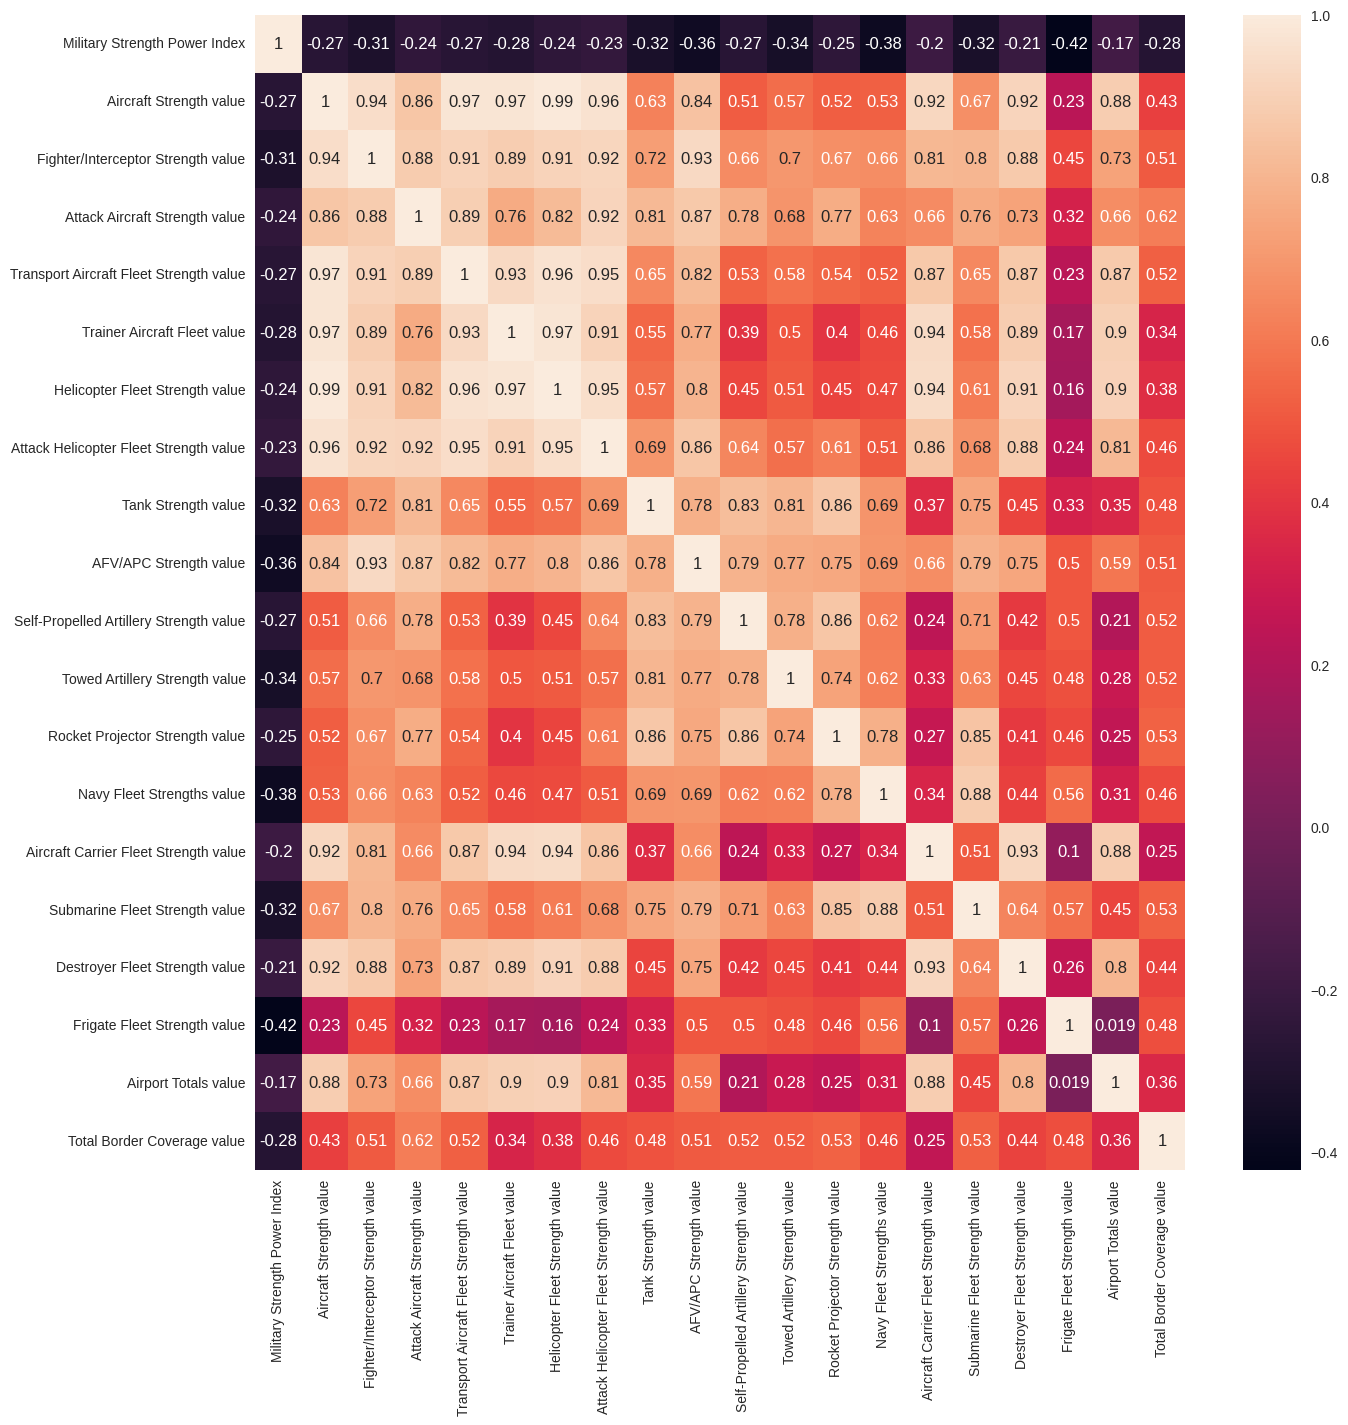

In [131]:
#displays a heatmap of feature correlations
plt.figure(figsize=(15,15))
sns.heatmap(df.corr(numeric_only=True),annot=True)

## Missing Values Filled

In [132]:
missing_rows = df[df['Navy Fleet Strengths value'].isna()]
missing_rows

,country,Military Strength Power Index,Aircraft Strength,Aircraft Strength value,Fighter/Interceptor Strength,Fighter/Interceptor Strength value,Attack Aircraft Strength,Attack Aircraft Strength value,Transport Aircraft Fleet Strength,Transport Aircraft Fleet Strength value,Trainer Aircraft Fleet,Trainer Aircraft Fleet value,Helicopter Fleet Strength,Helicopter Fleet Strength value,Attack Helicopter Fleet Strength,Attack Helicopter Fleet Strength value,Tank Strength,Tank Strength value,AFV/APC Strength,AFV/APC Strength value,Self-Propelled Artillery Strength,Self-Propelled Artillery Strength value,Towed Artillery Strength,Towed Artillery Strength value,Rocket Projector Strength,Rocket Projector Strength value,Navy Fleet Strengths,Navy Fleet Strengths value,Aircraft Carrier Fleet Strength,Aircraft Carrier Fleet Strength value,Submarine Fleet Strength,Submarine Fleet Strength value,Destroyer Fleet Strength,Destroyer Fleet Strength value,Frigate Fleet Strength,Frigate Fleet Strength value,defense spending budget,defense spending budget value,External Debt,External Debt value,Airport Totals,Airport Totals value,Oil Production,Oil Production value,Oil Consumption,Oil Consumption value,Proven Oil Reserves,Proven Oil Reserves value,Available Manpower,Available Manpower value,Total Population,Total Population value,Total Square Land Area,Total Square Land Area value,Total Coastline Coverage,Total Coastline Coverage value,Total Waterway Coverage,Total Waterway Coverage value,Total Border Coverage,Total Border Coverage value
16,Botswana,2.0582,Botswana,45,Botswana,10,Botswana,0,Botswana,11,Botswana,8,Botswana,16,Botswana,0,Botswana,55,Botswana,245,Botswana,0,Botswana,30,Botswana,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Botswana,"45,00,00,000",Botswana,"2,18,70,00,000",Botswana,74,Botswana,0,Botswana,16500,Botswana,0,Botswana,"9,62,617",Botswana,"22,49,104",Botswana,"5,81,730",NaN,NaN,Botswana,0,Botswana,4347.0
19,Burkina Faso,1.9009,Burkina Faso,16,Burkina Faso,0,Burkina Faso,3,Burkina Faso,1,Burkina Faso,4,Burkina Faso,8,Burkina Faso,2,Burkina Faso,0,Burkina Faso,350,Burkina Faso,0,Burkina Faso,0,Burkina Faso,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Burkina Faso,"13,00,00,000",Burkina Faso,"3,05,60,00,000",Burkina Faso,23,Burkina Faso,0,Burkina Faso,10500,Burkina Faso,0,Burkina Faso,"78,00,000",Burkina Faso,"1,97,42,715",Burkina Faso,"2,74,200",NaN,NaN,Burkina Faso,0,Burkina Faso,3611.0
23,Central African Republic,3.2889,Central African Republic,3,Central African Republic,0,Central African Republic,0,Central African Republic,2,Central African Republic,0,Central African Republic,1,Central African Republic,0,Central African Republic,4,Central African Republic,55,Central African Republic,0,Central African Republic,20,Central African Republic,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Central African Republic,"2,00,00,000",Central African Republic,"77,99,00,000",Central African Republic,39,Central African Republic,0,Central African Republic,4500,Central African Republic,0,Central African Republic,"23,48,581",Central African Republic,"57,45,062",Central African Republic,"6,22,984",NaN,NaN,Central African Republic,2800,Central African Republic,5920.0
24,Chad,1.6383,Chad,35,Chad,0,Chad,6,Chad,6,Chad,4,Chad,17,Chad,3,Chad,60,Chad,372,Chad,10,Chad,51,Chad,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Chad,"20,00,00,000",Chad,"1,72,40,00,000",Chad,59,Chad,"1,28,000",Chad,"1,00,000",Chad,"1,50,00,00,000",Chad,"60,30,834",Chad,"1,58,33,116",Chad,"12,84,000",NaN,NaN,Chad,0,Chad,6406.0
30,Czechia,0.5531,Czechia,95,Czechia,12,Czechia,16,Czechia,8,Czechia,15,Czechia,44,Czechia,15,Czechia,116,Czechia,682,Czechia,86,Czechia,85,Czechia,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Czechia,"2,96,90,00,000",Czechia,"2,05,20,00,00,000",Czechia,128,Czechia,2000,Czechia,"2,00,000",Czechia,"1,50,00,000",Czechia,"50,11,174",Czechia,"1,06,86,269",Czechia,78867,NaN,NaN,Czechia,664,Czechia,2046.0
38,Ethiopia,0.8581,Ethiopia,86,Ethiopia,24,Ethiopia,0,Ethiopia,9,Ethiopia

In [133]:
df.isnull().sum()

,0
country,0
Military Strength Power Index,0
Aircraft Strength,0
Aircraft Strength value,0
Fighter/Interceptor Strength,0
Fighter/Interceptor Strength value,0
Attack Aircraft Strength,0
Attack Aircraft Strength value,0
Transport Aircraft Fleet Strength,0
Transport Aircraft Fleet Strength value,0


In [134]:
df['Navy Fleet Strengths value'].fillna(0, inplace=True) # filled Missing Values with 0

In [135]:
df.head()

,country,Military Strength Power Index,Aircraft Strength,Aircraft Strength value,Fighter/Interceptor Strength,Fighter/Interceptor Strength value,Attack Aircraft Strength,Attack Aircraft Strength value,Transport Aircraft Fleet Strength,Transport Aircraft Fleet Strength value,Trainer Aircraft Fleet,Trainer Aircraft Fleet value,Helicopter Fleet Strength,Helicopter Fleet Strength value,Attack Helicopter Fleet Strength,Attack Helicopter Fleet Strength value,Tank Strength,Tank Strength value,AFV/APC Strength,AFV/APC Strength value,Self-Propelled Artillery Strength,Self-Propelled Artillery Strength value,Towed Artillery Strength,Towed Artillery Strength value,Rocket Projector Strength,Rocket Projector Strength value,Navy Fleet Strengths,Navy Fleet Strengths value,Aircraft Carrier Fleet Strength,Aircraft Carrier Fleet Strength value,Submarine Fleet Strength,Submarine Fleet Strength value,Destroyer Fleet Strength,Destroyer Fleet Strength value,Frigate Fleet Strength,Frigate Fleet Strength value,defense spending budget,defense spending budget value,External Debt,External Debt value,Airport Totals,Airport Totals value,Oil Production,Oil Production value,Oil Consumption,Oil Consumption value,Proven Oil Reserves,Proven Oil Reserves value,Available Manpower,Available Manpower value,Total Population,Total Population value,Total Square Land Area,Total Square Land Area value,Total Coastline Coverage,Total Coastline Coverage value,Total Waterway Coverage,Total Waterway Coverage value,Total Border Coverage,Total Border Coverage value
0,Afghanistan,1.3444,Afghanistan,260,Afghanistan,0,Afghanistan,25,Afghanistan,30,Afghanistan,0,Afghanistan,187,Afghanistan,0,Afghanistan,0,Afghanistan,1062,Afghanistan,0,Afghanistan,176,Afghanistan,50,Afghanistan,0.0,Afghanistan,0.0,Afghanistan,0.0,Afghanistan,0.0,Afghanistan,0.0,Afghanistan,"12,00,00,00,000",Afghanistan,"2,84,00,00,000",Afghanistan,43,Afghanistan,0,Afghanistan,5500,Afghanistan,0,Afghanistan,"1,43,25,743",Afghanistan,"3,49,40,837",Afghanistan,"6,52,230",Afghanistan,0,Afghanistan,1200,Afghanistan,5987.0
1,Albania,2.3137,Albania,19,Albania,0,Albania,0,Albania,0,Albania,0,Albania,19,Albania,0,Albania,0,Albania,467,Albania,0,Albania,0,Albania,0,Albania,38.0,Albania,0.0,Albania,0.0,Albania,0.0,Albania,0.0,Albania,"25,00,00,000",Albania,"9,50,50,00,000",Albania,4,Albania,16000,Albania,42500,Albania,"16,83,00,000",Albania,"15,19,438",Albania,"30,57,220",Albania,28748,Albania,362,Albania,41,Albania,691.0
2,Algeria,0.4659,Algeria,551,Algeria,103,Algeria,22,Algeria,59,Algeria,87,Algeria,257,Algeria,45,Algeria,880,Algeria,7361,Algeria,320,Algeria,240,Algeria,316,Algeria,201.0,Algeria,0.0,Algeria,6.0,Algeria,0.0,Algeria,5.0,Algeria,"13,00,00,00,000",Algeria,"6,26,00,00,000",Algeria,157,Algeria,"13,06,000",Algeria,"3,25,000",Algeria,"12,20,00,00,000",Algeria,"2,07,41,263",Algeria,"4,16,57,488",Algeria,"23,81,741",Algeria,998,Algeria,0,Algeria,6734.0
3,Angola,0.8379,Angola,295,Angola,72,Angola,18,Angola,30,Angola,47,Angola,126,Angola,15,Angola,379,Angola,595,Angola,28,Angola,357,Angola,115,Angola,57.0,Angola,0.0,Angola,0.0,Angola,0.0,Angola,0.0,Angola,"7,00,00,00,000",Angola,"42,08,00,00,000",Angola,176,Angola,"16,66,000",Angola,82300,Angola,"8,27,30,00,000",Angola,"62,44,205",Angola,"3,03,55,880",Angola,"12,46,700",Angola,1600,Angola,1300,Angola,5369.0
4,Argentina,0.6521,Argentina,227,Argentina,24,Argentina,7,Argentina,9,Argentina,64,Argentina,100,Argentina,0,Argentina,370,Argentina,739,Argentina,83,Argentina,172,Argentina,26,Argentina,49.0,Argentina,0.0,Argentina,2.0,Argentina,4.0,Argentina,0.0,Argentina,"4,20,00,00,000",Argentina,"2,14,90,00,00,000",Argentina,1138,Argentina,"4,79,400",Argentina,"6,85,000",Argentina,"2,18,50,00,000",Argentina,"2,01,79,430",Argentina,"4,46,94,198",Argentina,"27,80,400",Argentina,4989,Argentina,11000,Argentina,11968.0


In [136]:
missing_rows = df[df['Aircraft Carrier Fleet Strength'].isna()]
missing_rows['country']

,country
5,Armenia
7,Austria
11,Belarus
13,Bhutan
16,Botswana
19,Burkina Faso
23,Central African Republic
24,Chad
30,Czechia
38,Ethiopia


In [137]:
df['Aircraft Carrier Fleet Strength value'].fillna(0, inplace=True)

In [138]:
df.isnull().sum()

,0
country,0
Military Strength Power Index,0
Aircraft Strength,0
Aircraft Strength value,0
Fighter/Interceptor Strength,0
Fighter/Interceptor Strength value,0
Attack Aircraft Strength,0
Attack Aircraft Strength value,0
Transport Aircraft Fleet Strength,0
Transport Aircraft Fleet Strength value,0


In [139]:
df.at[110, 'Aircraft Carrier Fleet Strength'] = 2 # South Korea reportedly has 2 aircraft carriers

In [140]:
missing_rows = df[df['Submarine Fleet Strength value'].isna()]
missing_rows['country']

,country
5,Armenia
7,Austria
11,Belarus
13,Bhutan
16,Botswana
19,Burkina Faso
23,Central African Republic
24,Chad
30,Czechia
38,Ethiopia


In [141]:
df['Submarine Fleet Strength value'].fillna(0, inplace=True)
df.at[110, 'Submarine Fleet Strength value'] = 20

In [142]:
df.loc[[130]]

,country,Military Strength Power Index,Aircraft Strength,Aircraft Strength value,Fighter/Interceptor Strength,Fighter/Interceptor Strength value,Attack Aircraft Strength,Attack Aircraft Strength value,Transport Aircraft Fleet Strength,Transport Aircraft Fleet Strength value,Trainer Aircraft Fleet,Trainer Aircraft Fleet value,Helicopter Fleet Strength,Helicopter Fleet Strength value,Attack Helicopter Fleet Strength,Attack Helicopter Fleet Strength value,Tank Strength,Tank Strength value,AFV/APC Strength,AFV/APC Strength value,Self-Propelled Artillery Strength,Self-Propelled Artillery Strength value,Towed Artillery Strength,Towed Artillery Strength value,Rocket Projector Strength,Rocket Projector Strength value,Navy Fleet Strengths,Navy Fleet Strengths value,Aircraft Carrier Fleet Strength,Aircraft Carrier Fleet Strength value,Submarine Fleet Strength,Submarine Fleet Strength value,Destroyer Fleet Strength,Destroyer Fleet Strength value,Frigate Fleet Strength,Frigate Fleet Strength value,defense spending budget,defense spending budget value,External Debt,External Debt value,Airport Totals,Airport Totals value,Oil Production,Oil Production value,Oil Consumption,Oil Consumption value,Proven Oil Reserves,Proven Oil Reserves value,Available Manpower,Available Manpower value,Total Population,Total Population value,Total Square Land Area,Total Square Land Area value,Total Coastline Coverage,Total Coastline Coverage value,Total Waterway Coverage,Total Waterway Coverage value,Total Border Coverage,Total Border Coverage value
130,United States,0.0606,United States,13264,United States,2085,United States,715,United States,945,United States,2643,United States,5768,United States,967,United States,6289,United States,39253,United States,1465,United States,2740,United States,1366,United States,490.0,United States,20.0,United States,66.0,United States,91.0,United States,0.0,United States,"7,50,00,00,00,000",United States,"1,79,10,00,00,00,000",United States,13513,United States,"93,52,000",United States,"2,00,00,000",United States,"36,52,00,00,000",United States,"14,48,72,845",United States,"32,92,56,465",United States,"98,26,675",United States,19924,United States,41009,United States,12048.0


In [143]:
df.isnull().sum()

,0
country,0
Military Strength Power Index,0
Aircraft Strength,0
Aircraft Strength value,0
Fighter/Interceptor Strength,0
Fighter/Interceptor Strength value,0
Attack Aircraft Strength,0
Attack Aircraft Strength value,0
Transport Aircraft Fleet Strength,0
Transport Aircraft Fleet Strength value,0


In [144]:
missing_rows = df[df['Destroyer Fleet Strength value'].isna()]
missing_rows['country']

,country
5,Armenia
7,Austria
11,Belarus
13,Bhutan
16,Botswana
19,Burkina Faso
23,Central African Republic
24,Chad
30,Czechia
38,Ethiopia


In [145]:
df['Destroyer Fleet Strength value'].fillna(0, inplace=True)
df.at[110, 'Destroyer Fleet Strength value'] = 15

In [146]:
missing_rows = df[df['Frigate Fleet Strength value'].isna()]
missing_rows['country']

,country
5,Armenia
7,Austria
11,Belarus
13,Bhutan
16,Botswana
19,Burkina Faso
23,Central African Republic
24,Chad
30,Czechia
38,Ethiopia


In [147]:
df['Frigate Fleet Strength value'].fillna(0, inplace=True)
df.at[110, 'Frigate Fleet Strength value'] = 10

In [148]:
df.loc[[110]]

,country,Military Strength Power Index,Aircraft Strength,Aircraft Strength value,Fighter/Interceptor Strength,Fighter/Interceptor Strength value,Attack Aircraft Strength,Attack Aircraft Strength value,Transport Aircraft Fleet Strength,Transport Aircraft Fleet Strength value,Trainer Aircraft Fleet,Trainer Aircraft Fleet value,Helicopter Fleet Strength,Helicopter Fleet Strength value,Attack Helicopter Fleet Strength,Attack Helicopter Fleet Strength value,Tank Strength,Tank Strength value,AFV/APC Strength,AFV/APC Strength value,Self-Propelled Artillery Strength,Self-Propelled Artillery Strength value,Towed Artillery Strength,Towed Artillery Strength value,Rocket Projector Strength,Rocket Projector Strength value,Navy Fleet Strengths,Navy Fleet Strengths value,Aircraft Carrier Fleet Strength,Aircraft Carrier Fleet Strength value,Submarine Fleet Strength,Submarine Fleet Strength value,Destroyer Fleet Strength,Destroyer Fleet Strength value,Frigate Fleet Strength,Frigate Fleet Strength value,defense spending budget,defense spending budget value,External Debt,External Debt value,Airport Totals,Airport Totals value,Oil Production,Oil Production value,Oil Consumption,Oil Consumption value,Proven Oil Reserves,Proven Oil Reserves value,Available Manpower,Available Manpower value,Total Population,Total Population value,Total Square Land Area,Total Square Land Area value,Total Coastline Coverage,Total Coastline Coverage value,Total Waterway Coverage,Total Waterway Coverage value,Total Border Coverage,Total Border Coverage value
110,South Korea,0.1509,South Korea,1649,South Korea,414,South Korea,71,South Korea,41,South Korea,298,South Korea,803,South Korea,112,South Korea,2614,South Korea,14000,South Korea,3040,South Korea,3854,South Korea,575,South Korea,234.0,2,0.0,NaN,20.0,NaN,15.0,NaN,10.0,South Korea,"44,00,00,00,000",South Korea,"3,84,60,00,00,000",South Korea,111,South Korea,0,South Korea,"28,00,000",South Korea,0,South Korea,"2,57,09,049",South Korea,"5,14,18,097",South Korea,99720,South Korea,2413,South Korea,1600,South Korea,237.0


In [149]:
df.isnull().sum()

,0
country,0
Military Strength Power Index,0
Aircraft Strength,0
Aircraft Strength value,0
Fighter/Interceptor Strength,0
Fighter/Interceptor Strength value,0
Attack Aircraft Strength,0
Attack Aircraft Strength value,0
Transport Aircraft Fleet Strength,0
Transport Aircraft Fleet Strength value,0


In [150]:
missing_rows = df[df['Total Border Coverage value'].isna()]
missing_rows['country']

,country
6,Australia
9,Bahrain
57,Japan
69,Madagascar
83,New Zealand
95,Philippines
105,Singapore
113,Sri Lanka
119,Taiwan


In [151]:
df.loc[[6, 9, 57, 69, 83, 95, 105, 113, 119], 'Total Border Coverage value'] = [25760, 161, 2700, 4828, 2086, 36289, 193, 1340, 1500]

In [152]:
df_number = df.select_dtypes(include='number')
df_number = df[['country']].join(df_number)
df=df_number

In [153]:
df.head()

,country,Military Strength Power Index,Aircraft Strength value,Fighter/Interceptor Strength value,Attack Aircraft Strength value,Transport Aircraft Fleet Strength value,Trainer Aircraft Fleet value,Helicopter Fleet Strength value,Attack Helicopter Fleet Strength value,Tank Strength value,AFV/APC Strength value,Self-Propelled Artillery Strength value,Towed Artillery Strength value,Rocket Projector Strength value,Navy Fleet Strengths value,Aircraft Carrier Fleet Strength value,Submarine Fleet Strength value,Destroyer Fleet Strength value,Frigate Fleet Strength value,Airport Totals value,Total Border Coverage value
0,Afghanistan,1.3444,260,0,25,30,0,187,0,0,1062,0,176,50,0.0,0.0,0.0,0.0,0.0,43,5987.0
1,Albania,2.3137,19,0,0,0,0,19,0,0,467,0,0,0,38.0,0.0,0.0,0.0,0.0,4,691.0
2,Algeria,0.4659,551,103,22,59,87,257,45,880,7361,320,240,316,201.0,0.0,6.0,0.0,5.0,157,6734.0
3,Angola,0.8379,295,72,18,30,47,126,15,379,595,28,357,115,57.0,0.0,0.0,0.0,0.0,176,5369.0
4,Argentina,0.6521,227,24,7,9,64,100,0,370,739,83,172,26,49.0,0.0,2.0,4.0,0.0,1138,11968.0


In [154]:
df

,country,Military Strength Power Index,Aircraft Strength value,Fighter/Interceptor Strength value,Attack Aircraft Strength value,Transport Aircraft Fleet Strength value,Trainer Aircraft Fleet value,Helicopter Fleet Strength value,Attack Helicopter Fleet Strength value,Tank Strength value,AFV/APC Strength value,Self-Propelled Artillery Strength value,Towed Artillery Strength value,Rocket Projector Strength value,Navy Fleet Strengths value,Aircraft Carrier Fleet Strength value,Submarine Fleet Strength value,Destroyer Fleet Strength value,Frigate Fleet Strength value,Airport Totals value,Total Border Coverage value
0,Afghanistan,1.3444,260,0,25,30,0,187,0,0,1062,0,176,50,0.0,0.0,0.0,0.0,0.0,43,5987.0
1,Albania,2.3137,19,0,0,0,0,19,0,0,467,0,0,0,38.0,0.0,0.0,0.0,0.0,4,691.0
2,Algeria,0.4659,551,103,22,59,87,257,45,880,7361,320,240,316,201.0,0.0,6.0,0.0,5.0,157,6734.0
3,Angola,0.8379,295,72,18,30,47,126,15,379,595,28,357,115,57.0,0.0,0.0,0.0,0.0,176,5369.0
4,Argentina,0.6521,227,24,7,9,64,100,0,370,739,83,172,26,49.0,0.0,2.0,4.0,0.0,1138,11968.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
133,Venezuela,0.6449,260,38,0,52,82,86,10,390,600,73,104,36,49.0,0.0,2.0,0.0,4.0,444,5267.0
134,Vietnam,0.3559,293,77,0,38,36,138,25,2615,2530,70,1000,85,65.0,0.0,6.0,0.0,9.0,45,4616.0
135,Yemen,1.2412,169,77,0,8,21,61,14,620,615,20,85,150,30.0,0.0,0.0,0.0,0.0,57,1601.0
136,Zambia,1.6464,108,18,0,11,52,27,0,75,184,0,42,50,0.0,0.0,0.0,0.0,0.0,88,6043.0


## Modelling

In [155]:
x=df

In [156]:
x=pd.get_dummies(x,drop_first=True)

In [157]:
from sklearn.preprocessing import normalize, scale

In [158]:
x_normalize=normalize(x)

In [159]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [160]:
from yellowbrick.cluster import KElbowVisualizer

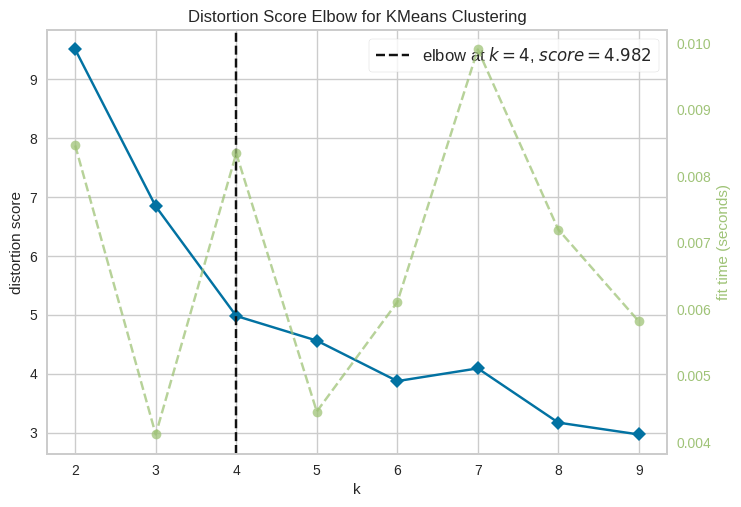

In [161]:
km=KMeans()
vis=KElbowVisualizer(km,k=(2,10))
vis.fit(x_normalize)
vis.show();

In [162]:
model=KMeans(4)

In [163]:
model=model.fit(x)

In [164]:
pred=model.predict(x)

In [165]:
pred

array([3, 0, 3, 3, 3, 0, 2, 0, 0, 0, 0, 0, 0, 0, 3, 0, 0, 3, 0, 0, 0, 3,
       3, 3, 3, 3, 1, 3, 0, 0, 0, 3, 0, 0, 0, 0, 0, 0, 3, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 3, 0, 3, 0, 0, 0, 0, 0, 0, 0, 3, 0, 0, 3, 3, 0, 0,
       0, 0, 0, 3, 0, 3, 3, 0, 0, 3, 0, 0, 3, 3, 0, 0, 0, 0, 0, 3, 0, 0,
       0, 0, 0, 3, 0, 3, 3, 2, 0, 0, 0, 3, 0, 1, 0, 0, 0, 0, 0, 0, 0, 3,
       0, 3, 0, 0, 3, 0, 0, 0, 0, 0, 0, 0, 3, 0, 0, 0, 0, 3, 0, 0, 1, 0,
       3, 3, 0, 0, 3, 0], dtype=int32)

In [166]:
x['cluster']=pred

In [167]:
df['cluster']=pred

In [168]:
silhouette_score(x,pred)

np.float64(0.39790371876029745)

In [169]:
df.head()

,country,Military Strength Power Index,Aircraft Strength value,Fighter/Interceptor Strength value,Attack Aircraft Strength value,Transport Aircraft Fleet Strength value,Trainer Aircraft Fleet value,Helicopter Fleet Strength value,Attack Helicopter Fleet Strength value,Tank Strength value,AFV/APC Strength value,Self-Propelled Artillery Strength value,Towed Artillery Strength value,Rocket Projector Strength value,Navy Fleet Strengths value,Aircraft Carrier Fleet Strength value,Submarine Fleet Strength value,Destroyer Fleet Strength value,Frigate Fleet Strength value,Airport Totals value,Total Border Coverage value,cluster
0,Afghanistan,1.3444,260,0,25,30,0,187,0,0,1062,0,176,50,0.0,0.0,0.0,0.0,0.0,43,5987.0,3
1,Albania,2.3137,19,0,0,0,0,19,0,0,467,0,0,0,38.0,0.0,0.0,0.0,0.0,4,691.0,0
2,Algeria,0.4659,551,103,22,59,87,257,45,880,7361,320,240,316,201.0,0.0,6.0,0.0,5.0,157,6734.0,3
3,Angola,0.8379,295,72,18,30,47,126,15,379,595,28,357,115,57.0,0.0,0.0,0.0,0.0,176,5369.0,3
4,Argentina,0.6521,227,24,7,9,64,100,0,370,739,83,172,26,49.0,0.0,2.0,4.0,0.0,1138,11968.0,3


## Data Visualization

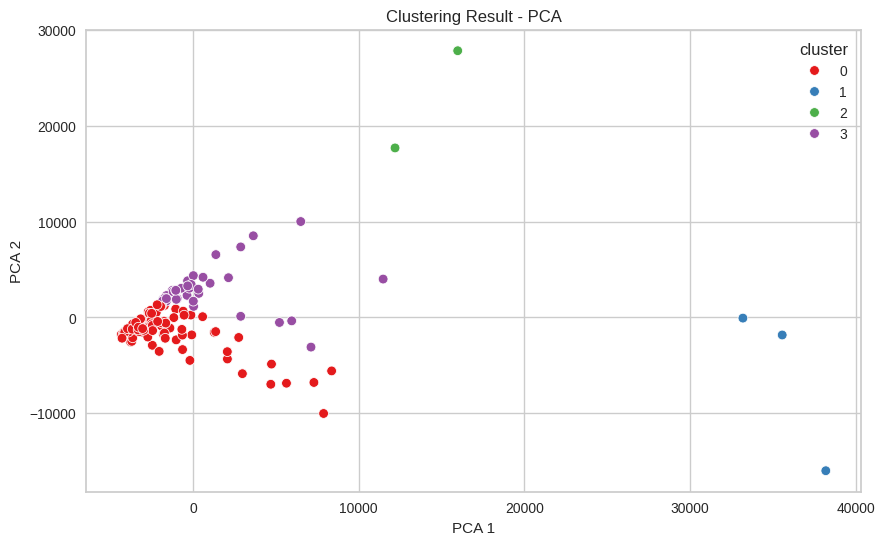

In [170]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# dimensionality reduction with PCA
pca = PCA(n_components=2)
pca_components = pca.fit_transform(df.drop(columns=["cluster", "country"]))

# scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(x=pca_components[:, 0], y=pca_components[:, 1], hue=df["cluster"], palette="Set1")
plt.title("Clustering Result - PCA")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.show()

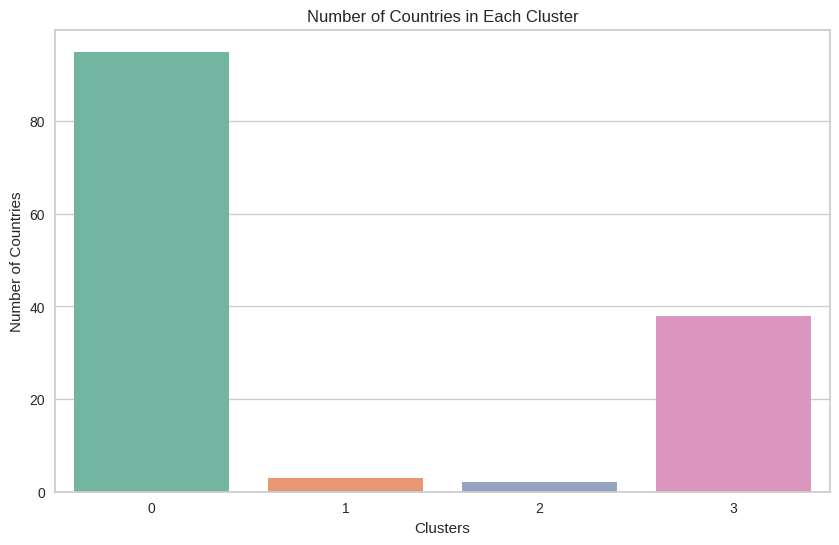

In [171]:
#counts the number of countries in each cluster
cluster_counts = df.groupby("cluster")["country"].count()

#bar plot
plt.figure(figsize=(10, 6))
sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Set2")
plt.xlabel("Clusters")
plt.ylabel("Number of Countries")
plt.title("Number of Countries in Each Cluster")
plt.show()

In [172]:
df.groupby("cluster")["country"].unique()

,country
cluster,
0,"[Albania, Armenia, Austria, Azerbaijan, Bahrai..."
1,"[China, Russia, United States]"
2,"[Australia, Philippines]"
3,"[Afghanistan, Algeria, Angola, Argentina, Boli..."


In [173]:
df[df["country"] == "Turkey"]["cluster"]

,cluster
124,0
